# Part 5g: does the rescue model get the aggregate right? A state-level hindcast

Part 5 tested the rescue model on individual properties (AUC 0.82). The headline, though, is an **aggregate**: units not rescued, added up by state. A reviewer will ask whether the model gets those totals right, or only ranks properties well. This notebook answers it the way a forecast would be checked: fit on lapses through 2015, predict every lapse from 2019 to 2023, and compare predicted with actual in units, by state (`src/hindcast.py`).

Two guards against flattering the model. First, the quantity the headline reports, **unrescued units**, is dominated by units that are not rescued under any model, so almost any method matches it; it is reported, but it cannot show skill. Second, the part the model actually predicts, **rescued units** and the **rescued share** of each state's lapsing units, is compared with simple benchmarks: lapsing units alone (which orders states by volume) and the training base rate applied to everything.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import hindcast as H
from viz import apply_style, SERIES, save_figure, BASELINE, INK_2, dot, MUTED

apply_style()
pd.set_option("display.width", 220)
tr, te = H.run("main")
S = H.summary(tr, te)
print(f"train {S['train_events']:,} lapses through 2015 (rescue rate {100 * S['train_rate']:.2f} %); test {S['test_events']:,} lapses 2019-2023 (observed {100 * S['test_rate']:.2f} %, mean predicted {100 * S['mean_predicted']:.2f} %)")

train 5,233 lapses through 2015 (rescue rate 1.11 %); test 4,640 lapses 2019-2023 (observed 2.20 %, mean predicted 1.26 %)


## 1. The aggregate the headline reports: unrescued units

In [2]:
rows = [("upper bound: property total units", S["unrescued_pred_upper"], S["unrescued_act_upper"]), ("lower bound: largest assisted subsidy", S["unrescued_pred_lower"], S["unrescued_act_lower"])]
agg = pd.DataFrame(rows, columns=["unit count", "predicted unrescued", "actual unrescued"]).set_index("unit count")
agg["predicted / actual"] = agg["predicted unrescued"] / agg["actual unrescued"]
display(agg.round(3))
print(f"state level ({S['states']} states): correlation of predicted with actual unrescued units {S['unrescued_pearson_model']:.3f}; lapsing units alone, no model, {S['unrescued_pearson_units_only']:.3f}")

,predicted unrescued,actual unrescued,predicted / actual
unit count,,,
upper bound: property total units,67862.929,68413.0,0.992
lower bound: largest assisted subsidy,50631.903,51326.0,0.986


state level (51 states): correlation of predicted with actual unrescued units 0.996; lapsing units alone, no model, 0.998


## 2. The part the model predicts: rescued units and the rescued share

In [3]:
g = H.state_table(te, S["train_rate"])
print(f"total rescued units: actual {S['rescued_total_act']:,.0f}; model {S['rescued_total_model']:,.0f} (ratio {S['rescued_total_model'] / S['rescued_total_act']:.2f}); training base rate {S['rescued_total_const']:,.0f} (ratio {S['rescued_total_const'] / S['rescued_total_act']:.2f})")
print(f"across states, rescued units: model Pearson {S['rescued_pearson_model']:.2f}, Spearman {S['rescued_spearman_model']:.2f}; lapsing units alone Pearson {S['rescued_pearson_units_only']:.2f}, Spearman {S['rescued_spearman_units_only']:.2f}")
print(f"across the {S['states_40plus']} states with 40 or more lapses, rescued SHARE of units, predicted against actual: Pearson {S['share_pearson']:.2f}, Spearman {S['share_spearman']:.2f}")

total rescued units: actual 5,030; model 5,580 (ratio 1.11); training base rate 814 (ratio 0.16)
across states, rescued units: model Pearson 0.76, Spearman 0.56; lapsing units alone Pearson 0.86, Spearman 0.65
across the 32 states with 40 or more lapses, rescued SHARE of units, predicted against actual: Pearson -0.07, Spearman -0.05


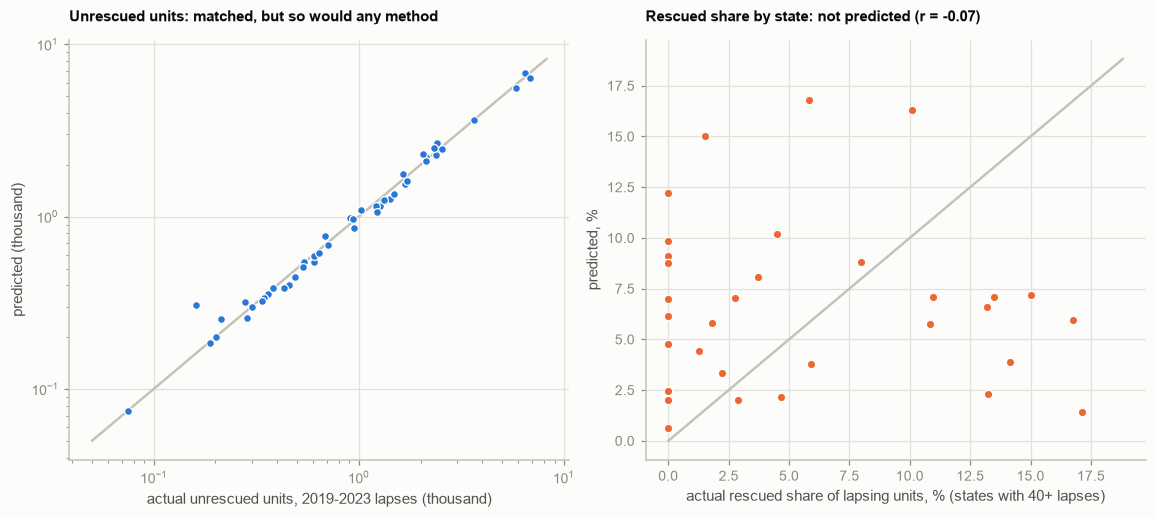

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.6))
ax = axs[0]
ax.scatter(g.unrescued_act / 1e3, g.unrescued_pred / 1e3, s=26, color=SERIES[0], edgecolor="white", linewidth=0.8, zorder=3)
lim = [0.05, 1.2 * g[["unrescued_act", "unrescued_pred"]].max().max() / 1e3]
ax.plot(lim, lim, color=BASELINE, lw=1.6); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("actual unrescued units, 2019-2023 lapses (thousand)"); ax.set_ylabel("predicted (thousand)")
ax.set_title("Unrescued units: matched, but so would any method", fontsize=10, loc="left")
ax = axs[1]
b = g[g.events >= 40]
ax.scatter(100 * b.share_act, 100 * b.share_pred, s=30, color=SERIES[1], edgecolor="white", linewidth=0.8, zorder=3)
m = max(100 * b.share_act.max(), 100 * b.share_pred.max()) * 1.1
ax.plot([0, m], [0, m], color=BASELINE, lw=1.6)
ax.set_xlabel("actual rescued share of lapsing units, % (states with 40+ lapses)"); ax.set_ylabel("predicted, %")
ax.set_title(f"Rescued share by state: not predicted (r = {S['share_pearson']:.2f})", fontsize=10, loc="left")
save_figure(fig, "57_state_hindcast", part="05_preservation")
plt.show()

## 3. Calibration: by year and by size

In [5]:
yr, sz = H.by_year(te), H.by_size(te)
display((yr.assign(predicted=100 * yr.predicted, observed=100 * yr.observed)).round(2))
sz.index = [f"{int(i.left) + 1 if i.left else 1} to {int(i.right) if i.right < 1e5 else '+'}" if i.right < 1e5 else f"over {int(i.left)}" for i in sz.index]
display((sz.assign(predicted=100 * sz.predicted, observed=100 * sz.observed)).round(2))

,predicted,observed,events,rescued
Y,,,,
2019.0,1.17,0.45,884,4
2020.0,0.98,0.82,970,8
2021.0,1.21,1.43,979,14
2022.0,1.15,3.94,938,37
2023.0,1.85,4.49,869,39


,predicted,observed,events,rescued
1 to 10,0.24,0.59,3237,19
11 to 25,1.27,4.18,693,29
26 to 50,2.81,5.21,365,19
51 to 100,5.58,10.80,213,23
101 to 200,11.95,10.53,95,10
over 200,23.34,5.41,37,2


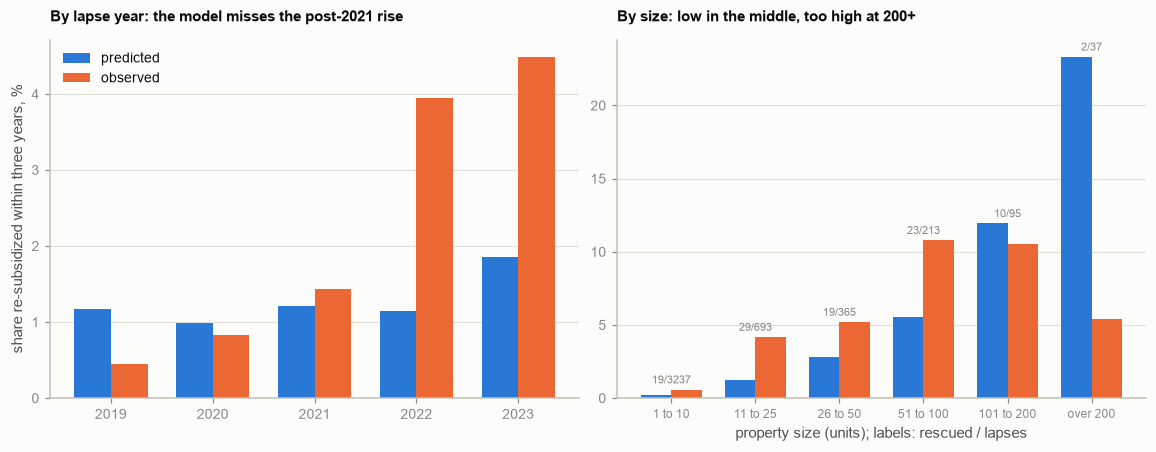

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.0))
x = np.arange(len(yr)); w = 0.36
ax = axs[0]
ax.bar(x - w / 2, 100 * yr.predicted, w, color=SERIES[0], label="predicted"); ax.bar(x + w / 2, 100 * yr.observed, w, color=SERIES[1], label="observed")
ax.set_xticks(x, [str(int(y)) for y in yr.index]); ax.set_ylabel("share re-subsidized within three years, %"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("By lapse year: the model misses the post-2021 rise", fontsize=10, loc="left")
ax = axs[1]
x = np.arange(len(sz))
ax.bar(x - w / 2, 100 * sz.predicted, w, color=SERIES[0], label="predicted"); ax.bar(x + w / 2, 100 * sz.observed, w, color=SERIES[1], label="observed")
for i, (n, r) in enumerate(zip(sz.events, sz.rescued)):
    ax.annotate(f"{int(r)}/{int(n)}", (i, max(100 * sz.predicted.iloc[i], 100 * sz.observed.iloc[i])), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=7.5, color=MUTED)
ax.set_xticks(x, sz.index, fontsize=8); ax.set_xlabel("property size (units); labels: rescued / lapses"); ax.grid(axis="x", visible=False)
ax.set_title("By size: low in the middle, too high at 200+", fontsize=10, loc="left")
save_figure(fig, "58_hindcast_calibration", part="05_preservation")
plt.show()

## Findings

**The aggregate holds up.** Trained on lapses through 2015, the model predicts 67,900 unrescued units for the 2019 to 2023 lapses against 68,400 actual (ratio 0.99; with the lower unit count 50,600 against 51,300), and across the 51 states the correlation of predicted with actual unrescued units is 0.996. The part of the headline built this way (units not rescued if the subsidy lapses) is right in level.

**But that agreement is easy and shows no skill.** Lapsing units alone, with no model, correlate 0.998 with the actual unrescued units, because about 97 percent of lapsing units are not rescued under any model. The informative test is the part the model predicts.

**Rescued units: right in level, no better than volume at ordering states.** Actual rescued units were 5,030; the model predicts 5,580 (11 percent high), while the flat training rate predicts 814 (the rate rose). Across states the model's rescued units correlate 0.76 with actual (Spearman 0.56), against 0.86 (0.65) for lapsing units alone. And **the rescued share of each state's lapsing units is not predicted at all**: across the 32 states with 40 or more lapses the correlation of predicted with actual is -0.07. State rescue shares run from 0 to 17 percent for reasons the model (size and program) does not contain. The consequence for the report: state differences in the HOME and HUD piece mostly reflect how many units are expiring and their size mix, not how likely each state is to rescue them; read that piece's state ranking as a ranking by volume.

**Calibration moved over time and by size.** By lapse year the model is close for 2019 to 2021 (predicted 1.0 to 1.2 percent, observed 0.5 to 1.4) and far low after: 2022 and 2023 observed 3.9 and 4.5 percent against 1.2 and 1.9 predicted. By size it is too low for small and mid-sized properties (observed 0.6, 4.2, 5.2, and 10.8 percent against 0.2, 1.3, 2.8, and 5.6 predicted for 1 to 10, 11 to 25, 26 to 50, and 51 to 100 units), about right for 101 to 200 units, and too high at over 200 units (23 percent predicted, 5 percent observed, 2 rescues in 37 lapses; the earlier 28 percent rate for large HUD-program properties comes from all years and a different mix).

**What it means.** Ranking properties by size works (Part 5), the national and state totals of unrescued units are right to within about 1 percent, but the level of rescue has moved since 2021 and state differences in rescue practice are not captured. The next notebook treats the post-2021 shift directly.

**Caveats.** One split (train through 2015, test 2019 to 2023); 102 rescued events in the test; state shares rest on few events (median 108 lapses per state with 40+); the 2022 and 2023 rise may reflect funding that is not in the data.